# Lecture 4–5 · Multiple Regression I and the Hat Matrix

Following `04_Multiple linear regression.pdf` (Kutner et al., 2005, Ch. 6) and `05_Hat Matrix.pdf`.

**Data:** `tips.csv`, $n=244$. $Y$ = `tip`, $X_1$ = `total_bill` (USD), $X_2$ = `size` (party size, 1–6).

$$Y_i=\beta_0+\beta_1X_{i1}+\beta_2X_{i2}+\varepsilon_i,\qquad p=3 .$$

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence

ALPHA = 0.05            # significance level
df = pd.read_csv('tips.csv')
X1 = df['total_bill'].to_numpy()
X2 = df['size'].to_numpy().astype(float)
Y  = df['tip'].to_numpy()
n  = len(Y)
print(df[['total_bill', 'size', 'tip']].describe().round(3))

       total_bill     size      tip
count     244.000  244.000  244.000
mean       19.786    2.570    2.998
std         8.902    0.951    1.384
min         3.070    1.000    1.000
25%        13.348    2.000    2.000
50%        17.795    2.000    2.900
75%        24.127    3.000    3.562
max        50.810    6.000   10.000


## Scatter plot matrix and correlations

The first diagnostic step (L4, slide 11).

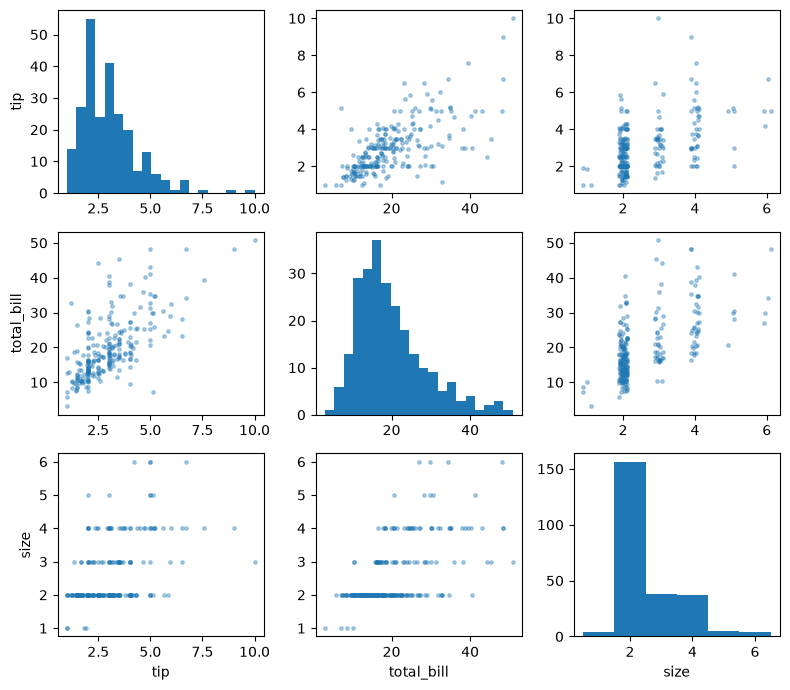

               tip  total_bill    size
tip         1.0000      0.6757  0.4893
total_bill  0.6757      1.0000  0.5983
size        0.4893      0.5983  1.0000


In [2]:
cols = ['tip', 'total_bill', 'size']
fig, ax = plt.subplots(3, 3, figsize=(8, 7))
for i, a in enumerate(cols):
    for j, b in enumerate(cols):
        if i == j:
            ax[i, j].hist(df[a], bins=20 if a != 'size' else np.arange(.5, 7.5, 1))
        else:
            jit = np.random.default_rng(0).uniform(-.12, .12, n) if b == 'size' else 0
            ax[i, j].scatter(df[b] + jit, df[a], s=6, alpha=.35)
        if i == 2: ax[i, j].set_xlabel(b)
        if j == 0: ax[i, j].set_ylabel(a)
plt.tight_layout()
plt.savefig('images/scatter_matrix.png')
plt.show()
print(df[cols].corr().round(4))

## Matrix formulation and least squares (6.25)

$$\mathbf b=(\mathbf X'\mathbf X)^{-1}\mathbf X'\mathbf Y,\qquad
\widehat{\operatorname{Var}}\{\mathbf b\}=MSE\,(\mathbf X'\mathbf X)^{-1}.$$

The first column of $\mathbf X$ is all ones.

In [3]:
Xmat = np.column_stack([np.ones(n), X1, X2])          # n x p, first column = intercept
p = Xmat.shape[1]
XtX = Xmat.T @ Xmat
XtX_inv = np.linalg.inv(XtX)
b = XtX_inv @ Xmat.T @ Y                               # (6.25)

Yhat = Xmat @ b
e = Y - Yhat
SSE = e @ e
MSE = SSE / (n - p)                                    # df = n - p
s_b = np.sqrt(np.diag(MSE * XtX_inv))                  # sqrt of diag of MSE (X'X)^-1
tcrit = stats.t.ppf(1 - ALPHA / 2, n - p)

print(f'n = {n}, p = {p}, error df = n - p = {n-p},  MSE = {MSE:.4f},  s = {np.sqrt(MSE):.4f}\n')
print(f'{"":<12}{"b":>10}{"s{b}":>10}{"t*":>9}{"P":>12}{"95% CI":>22}')
for name, bk, sk in zip(['intercept', 'total_bill', 'size'], b, s_b):
    t_ = bk / sk
    print(f'{name:<12}{bk:>10.4f}{sk:>10.4f}{t_:>9.3f}{2*stats.t.sf(abs(t_), n-p):>12.2e}'
          f'   [{bk - tcrit*sk:7.4f}, {bk + tcrit*sk:7.4f}]')

# cross-checks: statsmodels, and the normal equations themselves
fit_sm = sm.OLS(Y, Xmat).fit()
assert np.allclose(b, fit_sm.params) and np.allclose(s_b, fit_sm.bse), 'statsmodels disagrees'
assert np.allclose(XtX @ b, Xmat.T @ Y), 'normal equations not satisfied'
print('\nstatsmodels reproduces b and s{b}; (X\'X) b = X\'Y holds.')
print(f'\nFitted function: Yhat = {b[0]:.4f} + {b[1]:.4f} X1 + {b[2]:.4f} X2')

n = 244, p = 3, error df = n - p = 241,  MSE = 1.0272,  s = 1.0135

                     b      s{b}       t*           P                95% CI
intercept       0.6689    0.1936    3.455    6.50e-04   [ 0.2876,  1.0503]
total_bill      0.0927    0.0091   10.172    1.88e-20   [ 0.0748,  0.1107]
size            0.1926    0.0853    2.258    2.49e-02   [ 0.0245,  0.3607]

statsmodels reproduces b and s{b}; (X'X) b = X'Y holds.

Fitted function: Yhat = 0.6689 + 0.0927 X1 + 0.1926 X2


## Partial regression coefficients

$\beta_k$ is the change in $E\{Y\}$ per unit of $X_k$ **holding the other predictors constant** (L4, slide 6), so it
differs from the one-predictor slope when the predictors are correlated.

simple regression:   b1 = 0.1050  (tip per extra USD of bill, size ignored)
multiple regression: b1 = 0.0927  (holding party size fixed)
                     b2 = 0.1926  (USD per extra person, holding the bill fixed)

b1 changes by -11.7% once size is in the model; corr(total_bill, size) = 0.598


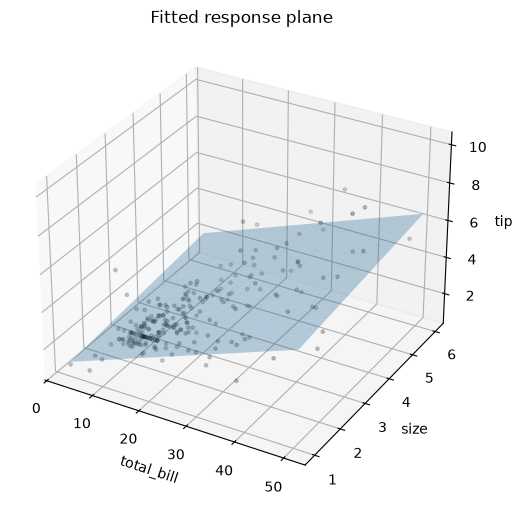

In [4]:
# simple regression of tip on total_bill (week 3), for comparison
b1_simple = ((X1 - X1.mean()) * (Y - Y.mean())).sum() / ((X1 - X1.mean())**2).sum()
print(f'simple regression:   b1 = {b1_simple:.4f}  (tip per extra USD of bill, size ignored)')
print(f'multiple regression: b1 = {b[1]:.4f}  (holding party size fixed)')
print(f'                     b2 = {b[2]:.4f}  (USD per extra person, holding the bill fixed)')
print(f'\nb1 changes by {100*(b[1]/b1_simple - 1):+.1f}% once size is in the model; '
      f'corr(total_bill, size) = {np.corrcoef(X1, X2)[0,1]:.3f}')

# the response surface is a plane
g1, g2 = np.meshgrid(np.linspace(X1.min(), X1.max(), 20), np.linspace(1, 6, 20))
fig = plt.figure(figsize=(7, 5.2))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(g1, g2, b[0] + b[1]*g1 + b[2]*g2, alpha=.3)
ax.scatter(X1, X2, Y, s=6, c='k', alpha=.5)
ax.set_xlabel('total_bill'); ax.set_ylabel('size'); ax.set_zlabel('tip')
ax.set_title('Fitted response plane')
plt.tight_layout()
plt.savefig('images/fitted_plane.png')
plt.show()

## ANOVA and the overall $F$ test

$$SSTO=SSR+SSE,\qquad F^*=\frac{MSR}{MSE}\sim F(p-1,\;n-p)\ \text{ under }H_0:\beta_1=\beta_2=0 .$$

In [5]:
SSTO = ((Y - Y.mean())**2).sum()
SSR  = SSTO - SSE
MSR  = SSR / (p - 1)
Fstar = MSR / MSE
Fcrit = stats.f.ppf(1 - ALPHA, p - 1, n - p)
Pval  = stats.f.sf(Fstar, p - 1, n - p)

print(f'{"Source":<12}{"SS":>12}{"df":>6}{"MS":>12}{"F*":>10}')
print(f'{"Regression":<12}{SSR:>12,.3f}{p-1:>6}{MSR:>12,.3f}{Fstar:>10.2f}')
print(f'{"Error":<12}{SSE:>12,.3f}{n-p:>6}{MSE:>12,.4f}')
print(f'{"Total":<12}{SSTO:>12,.3f}{n-1:>6}')
print(f'\nF({1-ALPHA:.2f}; {p-1}, {n-p}) = {Fcrit:.4f}   F* = {Fstar:.2f}   P = {Pval:.2e}')
print('->', 'reject H0: at least one predictor is related to tip' if Fstar > Fcrit else 'do not reject H0')
assert np.isclose(Fstar, fit_sm.fvalue) and np.isclose(SSR, fit_sm.ess), 'statsmodels disagrees'

Source                SS    df          MS        F*
Regression       217.659     2     108.829    105.95
Error            247.554   241      1.0272
Total            465.212   243

F(0.95; 2, 241) = 3.0333   F* = 105.95   P = 9.67e-34
-> reject H0: at least one predictor is related to tip


## $R^2$ and adjusted $R^2$

$$R^2=\frac{SSR}{SSTO},\qquad R^2_a=1-\frac{SSE/(n-p)}{SSTO/(n-1)} .$$

$R^2$ never decreases when a predictor is added; $R^2_a$ can (L4, slide 16). Checked by adding a noise column.

In [6]:
def r2_pair(Xm):
    k = Xm.shape[1]
    bb = np.linalg.lstsq(Xm, Y, rcond=None)[0]
    sse = ((Y - Xm @ bb)**2).sum()
    return 1 - sse / SSTO, 1 - (sse / (n - k)) / (SSTO / (n - 1))

R2, R2a = r2_pair(Xmat)
R2_s, R2a_s = r2_pair(Xmat[:, :2])
print(f'bill only        R2 = {R2_s:.4f}   R2_a = {R2a_s:.4f}')
print(f'bill + size      R2 = {R2:.4f}   R2_a = {R2a:.4f}')
print(f'\nabout {R2*100:.1f}% of the variation in tip is explained by bill and size together.')

rng_n = np.random.default_rng(5)
up_R2 = down_R2a = 0
K = 2000
for _ in range(K):
    r2n, r2an = r2_pair(np.column_stack([Xmat, rng_n.standard_normal(n)]))
    up_R2 += r2n >= R2 - 1e-12
    down_R2a += r2an < R2a
print(f'\nadding a column of pure noise, {K} times:')
print(f'  R2 did not decrease in {up_R2} of {K};   R2_a went down in {down_R2a} of {K}')

bill only        R2 = 0.4566   R2_a = 0.4544
bill + size      R2 = 0.4679   R2_a = 0.4635

about 46.8% of the variation in tip is explained by bill and size together.

adding a column of pure noise, 2000 times:
  R2 did not decrease in 2000 of 2000;   R2_a went down in 1370 of 2000


## Estimation and prediction at $\mathbf X_h$

$$\hat Y_h=\mathbf X_h'\mathbf b,\qquad
s^2\{\hat Y_h\}=MSE\;\mathbf X_h'(\mathbf X'\mathbf X)^{-1}\mathbf X_h,\qquad
s^2\{pred\}=MSE\left(1+\mathbf X_h'(\mathbf X'\mathbf X)^{-1}\mathbf X_h\right).$$

In [7]:
Xh = np.array([1.0, 20.0, 3.0])                 # a 20 USD bill for a party of 3
Yh = Xh @ b
q  = Xh @ XtX_inv @ Xh                          # X_h' (X'X)^-1 X_h
s_mean = np.sqrt(MSE * q)
s_pred = np.sqrt(MSE * (1 + q))

print(f'Xh = (1, {Xh[1]:.0f}, {Xh[2]:.0f})   Yhat_h = {Yh:.4f}\n')
print(f'mean response   s{{Yhat_h}} = {s_mean:.4f}   95% CI = [{Yh - tcrit*s_mean:.3f}, {Yh + tcrit*s_mean:.3f}]')
print(f'new observation s{{pred}}   = {s_pred:.4f}   95% PI = [{Yh - tcrit*s_pred:.3f}, {Yh + tcrit*s_pred:.3f}]')

pr = fit_sm.get_prediction(Xh.reshape(1, -1)).summary_frame(alpha=ALPHA)
assert np.allclose([pr['mean_se'][0], pr['mean_ci_lower'][0], pr['obs_ci_lower'][0]],
                   [s_mean, Yh - tcrit*s_mean, Yh - tcrit*s_pred]), 'statsmodels disagrees'
print('\nstatsmodels get_prediction reproduces both intervals.')

Xh = (1, 20, 3)   Yhat_h = 3.1010

mean response   s{Yhat_h} = 0.0740   95% CI = [2.955, 3.247]
new observation s{pred}   = 1.0162   95% PI = [1.099, 5.103]

statsmodels get_prediction reproduces both intervals.


## Diagnostics: residuals vs fitted, vs each predictor, vs $X_1X_2$

Chapter 3 tools carry over (L4, slides 19–22); a pattern against $X_1X_2$ would suggest a missing interaction.

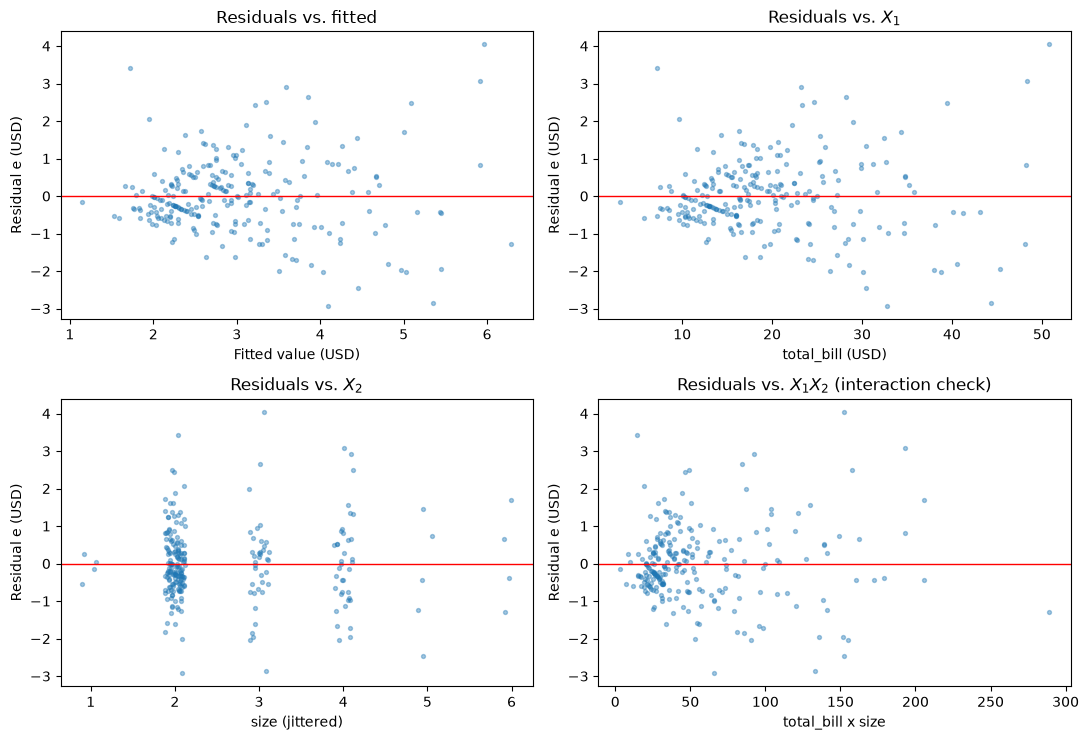

sd of residuals by fitted-value tercile:
  lowest   n =  81   mean e = -0.067   sd e = 0.681
  middle   n =  81   mean e = +0.126   sd e = 0.762
  highest  n =  82   mean e = -0.058   sd e = 1.415

corr(|e|, Yhat) = +0.4426
corr(e, X1*X2)  = +0.0067


In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
panels = [(Yhat, 'Fitted value (USD)', 'Residuals vs. fitted'),
          (X1, 'total_bill (USD)', 'Residuals vs. $X_1$'),
          (X2 + np.random.default_rng(1).uniform(-.12, .12, n), 'size (jittered)', 'Residuals vs. $X_2$'),
          (X1 * X2, 'total_bill x size', 'Residuals vs. $X_1X_2$ (interaction check)')]
for a, (h, lab, ttl) in zip(ax.ravel(), panels):
    a.scatter(h, e, s=8, alpha=.4)
    a.axhline(0, c='r', lw=1)
    a.set_xlabel(lab); a.set_ylabel('Residual e (USD)'); a.set_title(ttl)
plt.tight_layout()
plt.savefig('images/mr_residual_plots.png')
plt.show()

# numbers next to the pictures: spread of the residuals by fitted-value tercile
terc = np.digitize(Yhat, np.quantile(Yhat, [1/3, 2/3]))
print('sd of residuals by fitted-value tercile:')
for k, lab in enumerate(['lowest', 'middle', 'highest']):
    print(f'  {lab:<8} n = {(terc == k).sum():>3}   mean e = {e[terc == k].mean():+.3f}   sd e = {e[terc == k].std(ddof=1):.3f}')
print(f'\ncorr(|e|, Yhat) = {np.corrcoef(np.abs(e), Yhat)[0, 1]:+.4f}')
print(f'corr(e, X1*X2)  = {np.corrcoef(e, X1 * X2)[0, 1]:+.4f}')

### Constant variance and normality

**Breusch–Pagan:** regress $e_i^2$ on the predictors, $\chi^2_{BP}=\dfrac{SSR^*/2}{(SSE/n)^2}$ on $p-1$ df.
**Normal probability plot:** correlation of ordered residuals with their expected values, against a critical value
simulated from normal samples of the same size (as in week 3).

Breusch-Pagan: X2 = 92.227 on 2 df, P = 9.4e-21  ->  rejects constant variance at alpha = 0.05


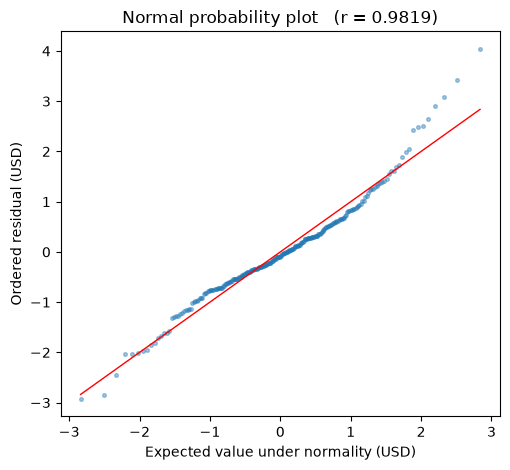

r = 0.9819;  simulated 5% critical value (n = 244) = 0.9943;  smallest of 2000 normal samples = 0.9895
-> reject normality at alpha = 0.05
skewness = +0.545   Shapiro-Wilk W = 0.9666, P = 1.78e-05


In [9]:
# Breusch-Pagan with p - 1 = 2 predictors
w = e**2
bw = np.linalg.lstsq(Xmat, w, rcond=None)[0]
SSR_star = ((Xmat @ bw - w.mean())**2).sum()
chi2_bp = (SSR_star / 2) / (SSE / n)**2
p_bp = stats.chi2.sf(chi2_bp, p - 1)
print(f'Breusch-Pagan: X2 = {chi2_bp:.3f} on {p-1} df, P = {p_bp:.3g}  ->  '
      f'{"rejects" if p_bp < ALPHA else "does not reject"} constant variance at alpha = {ALPHA}')

# normal probability plot
k = np.arange(1, n + 1)
expected = np.sqrt(MSE) * stats.norm.ppf((k - 0.375) / (n + 0.25))
ordered = np.sort(e)
r_npp = np.corrcoef(ordered, expected)[0, 1]

def npp_corr(sample):
    m = len(sample); kk = np.arange(1, m + 1)
    return np.corrcoef(np.sort(sample), stats.norm.ppf((kk - 0.375) / (m + 0.25)))[0, 1]
rng_sim = np.random.default_rng(0)
null_r = np.array([npp_corr(rng_sim.standard_normal(n)) for _ in range(2000)])
crit = np.percentile(null_r, 5)

plt.figure(figsize=(5.2, 4.8))
plt.scatter(expected, ordered, s=7, alpha=.4)
lim = [expected.min(), expected.max()]
plt.plot(lim, lim, 'r-', lw=1)
plt.xlabel('Expected value under normality (USD)'); plt.ylabel('Ordered residual (USD)')
plt.title(f'Normal probability plot   (r = {r_npp:.4f})')
plt.tight_layout()
plt.savefig('images/mr_normal_probability_plot.png')
plt.show()

print(f'r = {r_npp:.4f};  simulated 5% critical value (n = {n}) = {crit:.4f};  '
      f'smallest of 2000 normal samples = {null_r.min():.4f}')
print(f'-> {"reject" if r_npp < crit else "do not reject"} normality at alpha = {ALPHA}')
print(f'skewness = {stats.skew(e):+.3f}   Shapiro-Wilk W = {stats.shapiro(e).statistic:.4f}, '
      f'P = {stats.shapiro(e).pvalue:.3g}')

---

# Lecture 5 · The Hat Matrix

$$\hat{\mathbf Y}=\underbrace{\mathbf X(\mathbf X'\mathbf X)^{-1}\mathbf X'}_{\mathbf H}\,\mathbf Y,\qquad
\mathbf e=(\mathbf I-\mathbf H)\mathbf Y,\qquad \hat Y_i=\sum_j h_{ij}Y_j .$$

$\mathbf H$ is $n\times n$ and depends only on $\mathbf X$.

In [10]:
H = Xmat @ XtX_inv @ Xmat.T
I = np.eye(n)
print(f'H is {H.shape[0]} x {H.shape[1]};   rank of X = {np.linalg.matrix_rank(Xmat)} (= p, full column rank)\n')

def dev(A, B): return np.abs(A - B).max()
print('max absolute deviation (should be ~1e-12 or smaller):')
print(f'  Yhat = H Y             : {dev(H @ Y, Yhat):.2e}')
print(f'  e = (I - H) Y          : {dev((I - H) @ Y, e):.2e}')
print(f'  symmetric   H\' = H     : {dev(H.T, H):.2e}')
print(f'  idempotent  H H = H    : {dev(H @ H, H):.2e}')
print(f'  (I-H) idempotent       : {dev((I - H) @ (I - H), I - H):.2e}')
print(f'  H X = X                : {dev(H @ Xmat, Xmat):.2e}')
print(f'  (I - H) X = 0          : {dev((I - H) @ Xmat, 0):.2e}')
print(f'  row sums of H = 1      : {dev(H.sum(axis=1), 1):.2e}   (intercept in the model)')
print(f'\ntrace(H) = {np.trace(H):.6f}  (= p = {p});   trace(I - H) = {np.trace(I - H):.3f}  (= n - p = {n-p})')

H is 244 x 244;   rank of X = 3 (= p, full column rank)

max absolute deviation (should be ~1e-12 or smaller):
  Yhat = H Y             : 7.99e-15
  e = (I - H) Y          : 1.20e-14
  symmetric   H' = H     : 3.82e-17
  idempotent  H H = H    : 7.63e-17
  (I-H) idempotent       : 1.22e-15
  H X = X                : 6.39e-14
  (I - H) X = 0          : 6.75e-14
  row sums of H = 1      : 3.11e-15   (intercept in the model)

trace(H) = 3.000000  (= p = 3);   trace(I - H) = 241.000  (= n - p = 241)


## Geometry: a projection

$\hat{\mathbf Y}$ is the projection of $\mathbf Y$ onto the column space of $\mathbf X$; $\mathbf e$ is perpendicular to it.
With an intercept this is $SSTO=SSR+SSE$.

In [11]:
print(f"X'e = {np.round(Xmat.T @ e, 10)}   (e is orthogonal to every column of X)")
print(f"Yhat'e = {Yhat @ e:.3e}")
print(f'\n|Y - Ybar|^2   = {SSTO:,.4f}   SSTO')
print(f'|Yhat - Ybar|^2 = {((Yhat - Y.mean())**2).sum():,.4f}   SSR')
print(f'|e|^2           = {e @ e:,.4f}   SSE')
print(f'SSR + SSE       = {((Yhat - Y.mean())**2).sum() + e @ e:,.4f}')

X'e = [0. 0. 0.]   (e is orthogonal to every column of X)
Yhat'e = 1.990e-13

|Y - Ybar|^2   = 465.2125   SSTO
|Yhat - Ybar|^2 = 217.6586   SSR
|e|^2           = 247.5538   SSE
SSR + SSE       = 465.2125


## Use 1 — leverage $h_{ii}$

$h_{ii}$ measures how unusual a point's predictor values are. $0\le h_{ii}\le1$, $\sum_ih_{ii}=p$, mean $p/n$,
$h_{ii}\ge1/n$ with an intercept. Rule of thumb for high leverage: $h_{ii}>2p/n$.

min h = 0.00497  (>= 1/n = 0.00410: True)   max h = 0.07116  (<= 1)
sum h = 3.000000  (= p = 3)    mean h = 0.01230  (= p/n = 0.01230)
rule of thumb 2p/n = 0.02459:  22 of 244 cases exceed it

  row    bill  size    tip     h_ii  h/(p/n)
  170   50.81     3  10.00   0.0712     5.79
  143   27.05     6   5.00   0.0692     5.63
  125   29.80     6   4.20   0.0645     5.24
  156   48.17     6   5.00   0.0644     5.24
  141   34.30     6   6.70   0.0594     4.83
  184   40.55     2   3.00   0.0520     4.23
  182   45.35     3   3.50   0.0483     3.93
  212   48.33     4   9.00   0.0475     3.86


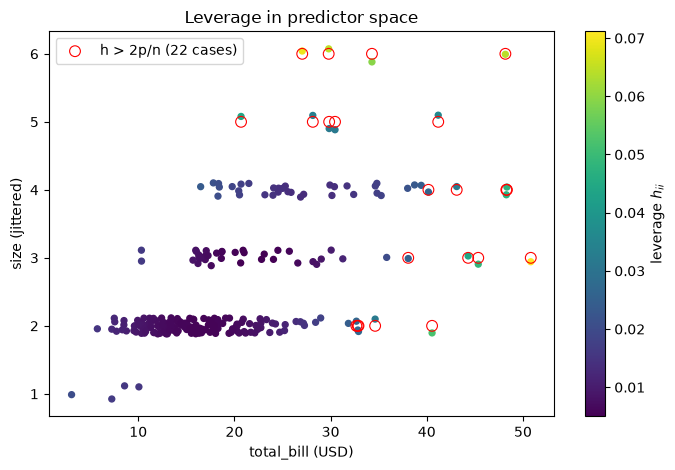

In [12]:
h = np.diag(H)
thr = 2 * p / n
print(f'min h = {h.min():.5f}  (>= 1/n = {1/n:.5f}: {h.min() >= 1/n - 1e-12})   max h = {h.max():.5f}  (<= 1)')
print(f'sum h = {h.sum():.6f}  (= p = {p})    mean h = {h.mean():.5f}  (= p/n = {p/n:.5f})')
print(f'rule of thumb 2p/n = {thr:.5f}:  {(h > thr).sum()} of {n} cases exceed it\n')

top = np.argsort(-h)[:8]
print(f'{"row":>5}{"bill":>8}{"size":>6}{"tip":>7}{"h_ii":>9}{"h/(p/n)":>9}')
for i in top:
    print(f'{i:>5}{X1[i]:>8.2f}{X2[i]:>6.0f}{Y[i]:>7.2f}{h[i]:>9.4f}{h[i]/(p/n):>9.2f}')

fig, ax = plt.subplots(figsize=(7, 4.8))
sc = ax.scatter(X1, X2 + np.random.default_rng(2).uniform(-.12, .12, n), c=h, s=18, cmap='viridis')
hi = h > thr
ax.scatter(X1[hi], X2[hi] + 0, facecolors='none', edgecolors='r', s=60, lw=.8, label=f'h > 2p/n ({hi.sum()} cases)')
plt.colorbar(sc, label='leverage $h_{ii}$')
ax.set_xlabel('total_bill (USD)'); ax.set_ylabel('size (jittered)')
ax.set_title('Leverage in predictor space'); ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('images/leverage_plot.png')
plt.show()

Also $s^2\{\hat Y_i\}=MSE\cdot h_{ii}$, since $\operatorname{Var}\{\hat{\mathbf Y}\}=\sigma^2\mathbf H$.

In [13]:
s_fit_i = np.sqrt(MSE * h)
pr_all = fit_sm.get_prediction(Xmat).summary_frame()
assert np.allclose(s_fit_i, pr_all['mean_se']), 'statsmodels disagrees'
print(f's{{Yhat_i}} = sqrt(MSE h_ii) agrees with statsmodels for all {n} cases.')
print(f'range: {s_fit_i.min():.4f} (lowest leverage) to {s_fit_i.max():.4f} (highest leverage)')

# the new point of the estimation section, compared with the observed cloud ("hidden extrapolation", textbook)
print(f'\nX_h\'(X\'X)^-1 X_h for the point (20, 3) used above = {q:.5f};   largest observed h_ii = {h.max():.5f}')
Xh2 = np.array([1.0, 50.0, 1.0])
q2 = Xh2 @ XtX_inv @ Xh2
print(f'for (bill 50, size 1): {q2:.5f}  -> {"outside" if q2 > h.max() else "inside"} the range of observed leverages, '
      f'although 50 and 1 are each inside the observed range of their own variable')

s{Yhat_i} = sqrt(MSE h_ii) agrees with statsmodels for all 244 cases.
range: 0.0715 (lowest leverage) to 0.2704 (highest leverage)

X_h'(X'X)^-1 X_h for the point (20, 3) used above = 0.00533;   largest observed h_ii = 0.07116
for (bill 50, size 1): 0.13835  -> outside the range of observed leverages, although 50 and 1 are each inside the observed range of their own variable


## Use 2 — residual variance and studentized residuals

$\operatorname{Var}\{e_i\}=\sigma^2(1-h_{ii})$: high-leverage points have smaller residual variance.

$$r_i=\frac{e_i}{\sqrt{MSE\,(1-h_{ii})}} .$$

In [14]:
e_semi = e / np.sqrt(MSE)
r_stud = e / np.sqrt(MSE * (1 - h))

infl = OLSInfluence(fit_sm)
assert np.allclose(r_stud, infl.resid_studentized_internal), 'statsmodels disagrees'
print('internally studentized residuals agree with statsmodels.\n')

print(f'max |semistudentized e*| = {np.abs(e_semi).max():.4f}    max |studentized r| = {np.abs(r_stud).max():.4f}')
print(f'cases with |e*| > 3: {(np.abs(e_semi) > 3).sum()}      cases with |r| > 3: {(np.abs(r_stud) > 3).sum()}')
print(f'ratio r_i / e*_i = 1/sqrt(1 - h_ii) ranges from {(r_stud/e_semi)[np.abs(e_semi)>1e-8].min():.4f} to '
      f'{(r_stud/e_semi)[np.abs(e_semi)>1e-8].max():.4f}\n')

flag = np.argsort(-np.abs(r_stud))[:6]
print(f'{"row":>5}{"bill":>8}{"size":>6}{"tip":>7}{"Yhat":>8}{"e":>8}{"h_ii":>8}{"e*":>8}{"r":>8}')
for i in flag:
    print(f'{i:>5}{X1[i]:>8.2f}{X2[i]:>6.0f}{Y[i]:>7.2f}{Yhat[i]:>8.2f}{e[i]:>8.2f}{h[i]:>8.4f}{e_semi[i]:>8.2f}{r_stud[i]:>8.2f}')

internally studentized residuals agree with statsmodels.

max |semistudentized e*| = 3.9886    max |studentized r| = 4.1386
cases with |e*| > 3: 3      cases with |r| > 3: 3
ratio r_i / e*_i = 1/sqrt(1 - h_ii) ranges from 1.0025 to 1.0376

  row    bill  size    tip    Yhat       e    h_ii      e*       r
  170   50.81     3  10.00    5.96    4.04  0.0712    3.99    4.14
  172    7.25     2   5.15    1.73    3.42  0.0126    3.38    3.40
  212   48.33     4   9.00    5.92    3.08  0.0475    3.04    3.11
  237   32.83     2   1.17    4.10   -2.93  0.0269   -2.89   -2.93
  183   23.17     4   6.50    3.59    2.91  0.0151    2.87    2.90
  102   44.30     3   2.50    5.35   -2.85  0.0445   -2.82   -2.88


## Use 3 — influence

High leverage is only potential influence; combined with a large residual it can move the fit. Cook's distance
(the slides name it without a formula; the textbook form is used):

$$D_i=\frac{e_i^2}{p\,MSE}\cdot\frac{h_{ii}}{(1-h_{ii})^2}=\frac{r_i^2}{p}\cdot\frac{h_{ii}}{1-h_{ii}} .$$

Cook's distance agrees with statsmodels.

  row    bill  size    tip    h_ii       r      D_i
  170   50.81     3  10.00  0.0712    4.14   0.4374
  212   48.33     4   9.00  0.0475    3.11   0.1612
  102   44.30     3   2.50  0.0445   -2.88   0.1287
  237   32.83     2   1.17  0.0269   -2.93   0.0790
  187   30.46     5   2.00  0.0317   -2.46   0.0661
  182   45.35     3   3.50  0.0483   -1.97   0.0659

largest D = 0.4374.  The case with the highest leverage (row 170) has D = 0.4374; the case with the largest |r| (row 170) has D = 0.4374.


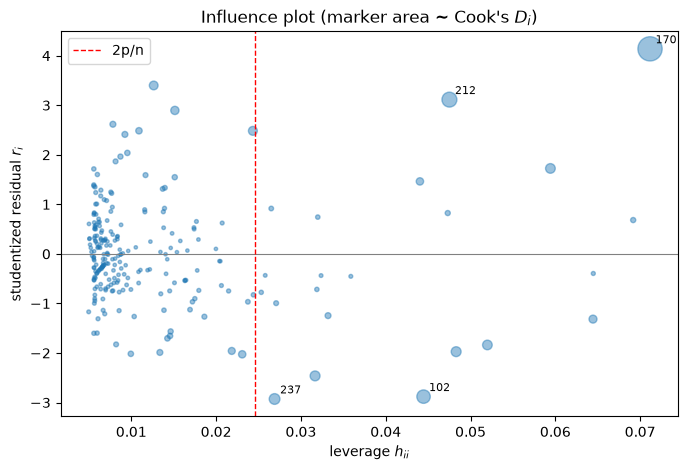

In [15]:
D = e**2 / (p * MSE) * h / (1 - h)**2
assert np.allclose(D, infl.cooks_distance[0]), 'statsmodels disagrees'
print('Cook\'s distance agrees with statsmodels.\n')

top_d = np.argsort(-D)[:6]
print(f'{"row":>5}{"bill":>8}{"size":>6}{"tip":>7}{"h_ii":>8}{"r":>8}{"D_i":>9}')
for i in top_d:
    print(f'{i:>5}{X1[i]:>8.2f}{X2[i]:>6.0f}{Y[i]:>7.2f}{h[i]:>8.4f}{r_stud[i]:>8.2f}{D[i]:>9.4f}')
print(f'\nlargest D = {D.max():.4f}.  The case with the highest leverage (row {h.argmax()}) has D = {D[h.argmax()]:.4f}; '
      f'the case with the largest |r| (row {np.abs(r_stud).argmax()}) has D = {D[np.abs(r_stud).argmax()]:.4f}.')

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.scatter(h, r_stud, s=300 * D / D.max() + 6, alpha=.45)
ax.axhline(0, c='gray', lw=.8); ax.axvline(thr, c='r', ls='--', lw=1, label='2p/n')
for i in top_d[:4]:
    ax.annotate(str(i), (h[i], r_stud[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('leverage $h_{ii}$'); ax.set_ylabel('studentized residual $r_i$')
ax.set_title("Influence plot (marker area ~ Cook's $D_i$)"); ax.legend()
plt.tight_layout()
plt.savefig('images/influence_plot.png')
plt.show()

In [16]:
# sensitivity: refit without the three cases with the largest Cook's distance
drop = top_d[:3]
keep = np.setdiff1d(np.arange(n), drop)
b_drop = np.linalg.lstsq(Xmat[keep], Y[keep], rcond=None)[0]
print(f'dropped rows {[int(i) for i in drop]}')
print(f'{"":<12}{"all cases":>12}{"without":>12}{"change":>10}')
for name, b_all, b_wo in zip(['intercept', 'total_bill', 'size'], b, b_drop):
    print(f'{name:<12}{b_all:>12.4f}{b_wo:>12.4f}{100*(b_wo/b_all - 1):>+9.1f}%')

dropped rows [170, 212, 102]
               all cases     without    change
intercept         0.6689      0.7733    +15.6%
total_bill        0.0927      0.0816    -12.0%
size              0.1926      0.2296    +19.2%


## Summary

- $\hat Y=0.669+0.0927X_1+0.1926X_2$; overall $F^*=105.95$ rejects $\beta_1=\beta_2=0$, but $R^2=0.468$ is only
  $0.011$ above the bill-only fit.
- Constant variance (Breusch–Pagan) and normality are both rejected, as in week 3.
- $\mathbf H$ is symmetric and idempotent with $\operatorname{tr}\mathbf H=p$; 22 of 244 cases exceed $2p/n$.
- Row 170 (bill 50.81) has the highest leverage, the largest residual ($r=4.14$) and the largest Cook's $D$ ($0.437$);
  dropping the three largest-$D$ cases shifts the coefficients by 12–19%.